# 06 — Dissertation Figures (Priority A/B quantitative set)

Generates every quantitative dissertation figure (A-H) directly from the final scope-corrected dataset, the target-specific primary/composition cohorts, the persisted Notebook 03 OOF artifact, and Notebook 05's bootstrap logic. No retraining, no new experiments, no cohort/feature/metric changes.

Styling constants (colour-blind-safe palette, target/model colours, panel-label helper, multi-format save helper) live in `literature_pipeline/modelling/figure_style.py` — this notebook configures inputs and calls that shared code, following the project's convention of not duplicating reusable logic inline.

Outputs: `figures/dissertation/*.png`. No figure carries an internal dissertation title anywhere below — structural panel letters and axis-style column labels are kept, since a figure needs those to be legible at all.


## Imports and shared inputs (loaded once, reused by every figure below)


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "modelling" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from literature_pipeline.modelling import modelling_lib as ml
from literature_pipeline.modelling import dataset_contract as dc
from literature_pipeline.modelling import figure_style as fs

OUT_DIR = PROJECT_ROOT / "figures" / "dissertation"
FINAL_DATASET_PATH = PROJECT_ROOT / "data" / "datasets_v2" / "production_run" / "cpp_dataset_v2.csv"
OOF_ARTIFACT_PATH = PROJECT_ROOT / "data" / "modelling_results" / "notebook03_oof_predictions.csv"
SCOPE_AUDIT_PATH = PROJECT_ROOT / "docs" / "scope_audit_v1.csv"
IDENTITY_COLS = ["doi", "material_id", "condition_id", "observation_id"]
TARGET_ORDER = fs.TARGET_ORDER

df_raw = pd.read_csv(FINAL_DATASET_PATH)
df = ml.apply_known_data_corrections(df_raw)
assert len(df) == 256 and df["doi"].nunique() == 44, "dataset does not match the frozen 256/44 manifest -- STOP"
target_configs = ml.build_target_configs(df)

oof_artifact = pd.read_csv(OOF_ARTIFACT_PATH)
EXPECTED_N = {"UTS_MPa": 94, "YS_MPa": 95, "elongation_pct": 52}
EXPECTED_DOI = {"UTS_MPa": 19, "YS_MPa": 20, "elongation_pct": 12}
for target in TARGET_ORDER:
    for model_name, g in oof_artifact[oof_artifact["target"] == target].groupby("model"):
        assert len(g) == EXPECTED_N[target] and g["doi"].nunique() == EXPECTED_DOI[target], \
            f"{target}/{model_name}: OOF artifact does not match frozen cohort sizes -- STOP"

print(f"df: {df.shape}, {df['doi'].nunique()} DOI (scope-corrected)")
print(f"oof_artifact: {len(oof_artifact)} rows, targets={sorted(oof_artifact['target'].unique())}, "
      f"models={sorted(oof_artifact['model'].unique())}")
for target in TARGET_ORDER:
    cfg = target_configs[target]
    print(f"{target}: {len(cfg['feature_sets']['composition'])} selected features, "
          f"model_target_column={cfg['model_target_column']!r}")


df: (256, 55), 44 DOI (scope-corrected)
oof_artifact: 1205 rows, targets=['UTS_MPa', 'YS_MPa', 'elongation_pct'], models=['dummy_mean', 'gradient_boosting', 'random_forest', 'ridge', 'svr']
UTS_MPa: 10 selected features, model_target_column='UTS_MPa_corrected'
YS_MPa: 10 selected features, model_target_column='YS_MPa'
elongation_pct: 7 selected features, model_target_column='elongation_pct'


## Figure A — dataset construction and scope-audit outcome

Observation-level counts only (297 → 256); the 871-publication corpus size isn't combined into this figure, since publications and observations are different units and are kept apart by design. Panel 2 breaks down the 41 removed observations by confirmed non-steel/mixed-material category, read directly from `docs/scope_audit_v1.csv` (the version-controlled audit table), not hand-typed.


In [2]:
scope_audit = pd.read_csv(SCOPE_AUDIT_PATH)
excluded_audit = scope_audit[scope_audit["scope_status"] != "steel"].copy()
assert excluded_audit["n_final_observations"].sum() == 41, "excluded-observation total does not match 41 -- STOP"

# The 7 excluded DOI are NOT one uniform category: 6 are wholly non-steel materials,
# 1 (Cu-foil) is mixed_material -- the paper is genuinely about steel welding, but the
# only material that reached the final extracted cohort from it was a copper tramp-element
# insert, not the paper's own steel base metal. Verified, not assumed.
status_totals = excluded_audit.groupby("scope_status")["n_final_observations"].agg(["sum", "count"])
assert status_totals.loc["non_steel", "count"] == 6 and status_totals.loc["non_steel", "sum"] == 39, \
    "expected 6 non_steel DOI totalling 39 observations -- STOP"
assert status_totals.loc["mixed_material", "count"] == 1 and status_totals.loc["mixed_material", "sum"] == 2, \
    "expected 1 mixed_material DOI totalling 2 observations -- STOP"
print(status_totals)

# Short, evidence-sourced category labels (from each row's own evidence_rationale in the
# audit CSV -- see the printed rationale text below for the exact source sentence).
CATEGORY_LABELS = {
    "10.1007/s40962-026-02006-1": "Al casting alloy\n(A356)",
    "10.1007/s10973-026-15761-4": "Al wrought alloy\n(AA7075)",
    "10.1007/s11665-026-14678-1": "Ni superalloy\n(Inconel 718)",
    "10.1007/s40194-026-02341-1": "Cu-foil\n(mixed material)",
    "10.1007/s40830-026-00604-w": "NiTi shape-memory\nalloy",
    "10.1007/s40962-025-01715-3": "Al alloy\n(new Al-Mg)",
    "10.1007/s42114-025-01547-z": "CuCrZr/Cu\ncomposite",
}
assert set(CATEGORY_LABELS) == set(excluded_audit["doi"]), "category label mapping does not match audit DOI set -- STOP"
excluded_audit["category_label"] = excluded_audit["doi"].map(CATEGORY_LABELS)
excluded_audit = excluded_audit.sort_values("n_final_observations", ascending=True)

for _, r in excluded_audit.iterrows():
    print(r["doi"], f"[{r['scope_status']}]", "->", r["evidence_rationale"][:90])


                sum  count
scope_status              
mixed_material    2      1
non_steel        39      6
10.1007/s42114-025-01547-z [non_steel] -> Title: "...CuCrZr/Cu laminated metallic composites..." -- copper-based composite
10.1007/s40194-026-02341-1 [mixed_material] -> Title: "...tramp elements in resistance spot welding" (paper is about steel welding); but 
10.1007/s40830-026-00604-w [non_steel] -> Title: "...Wrought NiTi Shape Memory Alloys" -- nickel-titanium, not iron-based
10.1007/s40962-025-01715-3 [non_steel] -> Title: "Development of New Aluminium Alloys..."; grade_label Al-Mg
10.1007/s11665-026-14678-1 [non_steel] -> Title: "...Cold-Sprayed Inconel 718 Coatings"; grade_label IN718 -- nickel-based superallo
10.1007/s10973-026-15761-4 [non_steel] -> Title: "...7075-alloy..."; grade_label AA7075 -- wrought aluminium alloy (Aluminum Associa
10.1007/s40962-026-02006-1 [non_steel] -> Title: "...AlSi7Mg0.3 (A356) Casting Alloy" -- aluminium casting alloy (materials M1/M3 = 


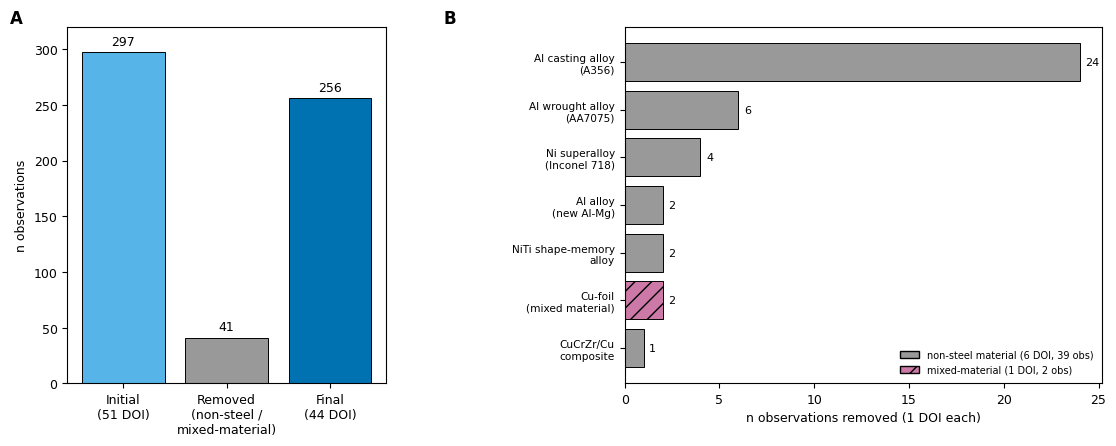

png: figures/dissertation/figA_dataset_construction_scope_audit.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.5]})

ax = axes[0]
n_initial, n_removed, n_final = 297, 41, 256
bars = ax.bar(["Initial\n(51 DOI)", "Removed\n(non-steel /\nmixed-material)", "Final\n(44 DOI)"],
              [n_initial, n_removed, n_final],
              color=[fs.OKABE_ITO["sky_blue"], fs.OKABE_ITO["grey"], fs.OKABE_ITO["blue"]],
              edgecolor="black", linewidth=0.7)
for b, v in zip(bars, [n_initial, n_removed, n_final]):
    ax.text(b.get_x() + b.get_width() / 2, v + 4, str(v), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("n observations")
ax.set_ylim(0, 320)
fs.add_panel_label(ax, "A", x=-0.18)

ax = axes[1]
y = np.arange(len(excluded_audit))
STATUS_COLOR = {"non_steel": fs.OKABE_ITO["grey"], "mixed_material": fs.OKABE_ITO["reddish_purple"]}
STATUS_HATCH = {"non_steel": None, "mixed_material": "//"}
bar_colors = excluded_audit["scope_status"].map(STATUS_COLOR)
bar_hatches = excluded_audit["scope_status"].map(STATUS_HATCH)
bars = ax.barh(y, excluded_audit["n_final_observations"], color=bar_colors, edgecolor="black", linewidth=0.7)
for b, h in zip(bars, bar_hatches):
    if h:
        b.set_hatch(h)
ax.set_yticks(y)
ax.set_yticklabels(excluded_audit["category_label"], fontsize=7.6)
ax.set_xlabel("n observations removed (1 DOI each)")
for yi, v in zip(y, excluded_audit["n_final_observations"]):
    ax.text(v + 0.3, yi, str(int(v)), va="center", fontsize=8)
fs.add_panel_label(ax, "B", x=-0.38)

legend_handles = [
    plt.matplotlib.patches.Patch(facecolor=STATUS_COLOR["non_steel"], edgecolor="black",
                                  label="non-steel material (6 DOI, 39 obs)"),
    plt.matplotlib.patches.Patch(facecolor=STATUS_COLOR["mixed_material"], edgecolor="black", hatch="//",
                                  label="mixed-material (1 DOI, 2 obs)"),
]
ax.legend(handles=legend_handles, loc="lower right", fontsize=7, frameon=False)

fig.subplots_adjust(left=0.08, right=0.98, top=0.95, bottom=0.14, wspace=0.6)
paths = fs.save_figure(fig, "figA_dataset_construction_scope_audit", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Figure B — final target distributions (primary-eligible) and observations per DOI

Uses the per-target `primary` cohort — unit-verified, scope-corrected, the same cohort as Figure 4's panel A previously, not the smaller composition-model cohort. A histogram plus a thin marginal boxplot per target; a separate wide panel below shows the observations-per-DOI distribution across the full 256/44 final steel dataset, as a plain count histogram with no 44-colour DOI legend.


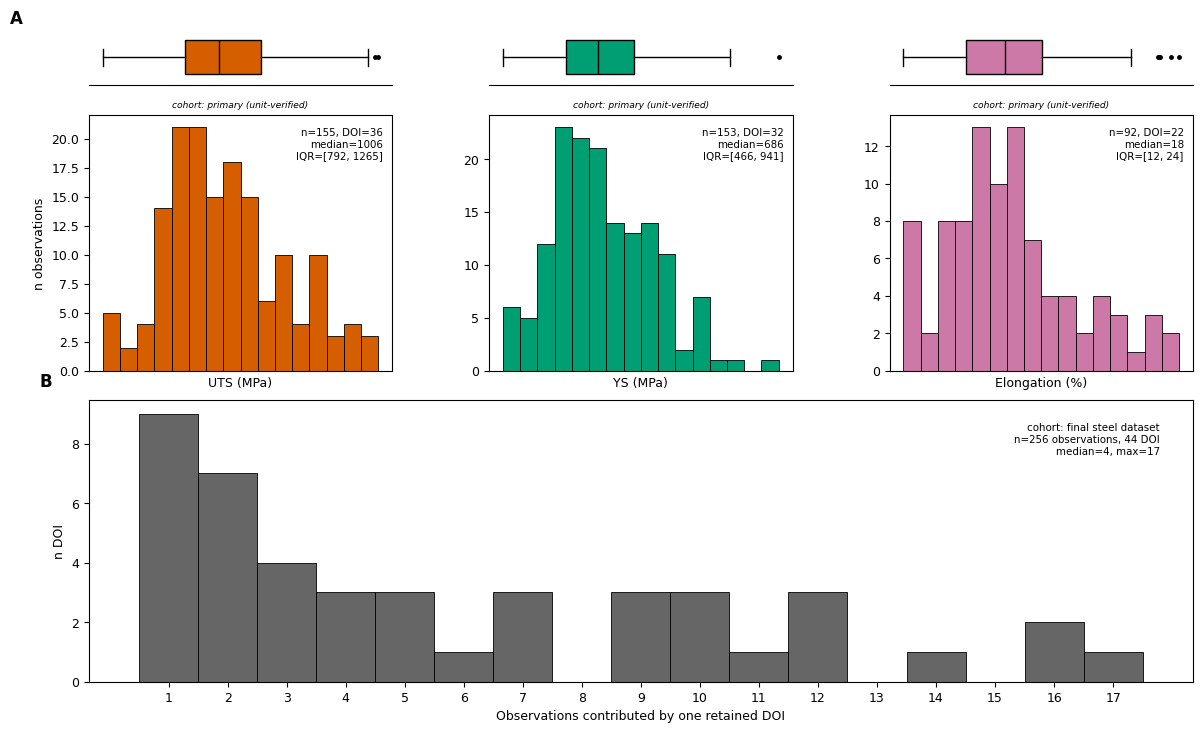

png: figures/dissertation/figB_target_distributions_publication_support.png


In [4]:
fig = plt.figure(figsize=(12, 7.5))
gs = fig.add_gridspec(3, 3, height_ratios=[0.22, 1.0, 1.1], hspace=0.15, wspace=0.32)

value_cols = {t: target_configs[t]["model_target_column"] for t in TARGET_ORDER}
for i, target in enumerate(TARGET_ORDER):
    primary_mask = ml.target_cohort_masks(df, target)["primary"]
    vals = df.loc[primary_mask, value_cols[target]].dropna()
    n_doi = df.loc[primary_mask, "doi"].nunique()

    ax_box = fig.add_subplot(gs[0, i])
    ax_box.boxplot(vals, vert=False, widths=0.6, patch_artist=True,
                    boxprops=dict(facecolor=fs.TARGET_COLORS[target], edgecolor="black"),
                    medianprops=dict(color="black"), showfliers=True,
                    flierprops=dict(marker="o", markersize=2.5, markerfacecolor="black"))
    ax_box.set_yticks([])
    ax_box.set_xticks([])
    for spine in ["top", "right", "left"]:
        ax_box.spines[spine].set_visible(False)
    if i == 0:
        fs.add_panel_label(ax_box, "A", x=-0.26, y=1.35)

    ax_hist = fig.add_subplot(gs[1, i], sharex=ax_box)
    ax_hist.hist(vals, bins=16, color=fs.TARGET_COLORS[target], edgecolor="black", linewidth=0.6)
    ax_hist.set_xlabel(fs.TARGET_DISPLAY[target])
    if i == 0:
        ax_hist.set_ylabel("n observations")
    med, q1, q3 = vals.median(), vals.quantile(0.25), vals.quantile(0.75)
    ax_hist.text(0.97, 0.95, f"n={len(vals)}, DOI={n_doi}\nmedian={med:.0f}\nIQR=[{q1:.0f}, {q3:.0f}]",
                 transform=ax_hist.transAxes, ha="right", va="top", fontsize=7.4,
                 bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
    ax_hist.text(0.5, 1.02, "cohort: primary (unit-verified)", transform=ax_hist.transAxes,
                 ha="center", va="bottom", fontsize=6.6, style="italic")

ax_c = fig.add_subplot(gs[2, :])
per_doi = df.groupby("doi").size()
max_n = int(per_doi.max())
bins = np.arange(1, max_n + 2) - 0.5
ax_c.hist(per_doi, bins=bins, color="#666666", edgecolor="black", linewidth=0.6)
ax_c.set_xlabel("Observations contributed by one retained DOI")
ax_c.set_ylabel("n DOI")
ax_c.set_xticks(range(1, max_n + 1))
ax_c.text(0.97, 0.92, f"cohort: final steel dataset\nn={len(df)} observations, {df['doi'].nunique()} DOI\n"
                       f"median={int(per_doi.median())}, max={max_n}",
          transform=ax_c.transAxes, ha="right", va="top", fontsize=7.4)
fs.add_panel_label(ax_c, "B", x=-0.045, y=1.1)

fig.subplots_adjust(left=0.06, right=0.98, top=0.95, bottom=0.08)
paths = fs.save_figure(fig, "figB_target_distributions_publication_support", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Figure C — composition-feature coverage (observation vs. DOI), per target's modelling cohort

Uses each target's own composition-model cohort (primary and at least one selected feature present — 94/19, 95/20, 52/12) and its own selected-feature list (10/10/7 elements). Paired bars distinguish observation coverage from DOI coverage explicitly, via `modelling_lib.composition_coverage_table`.


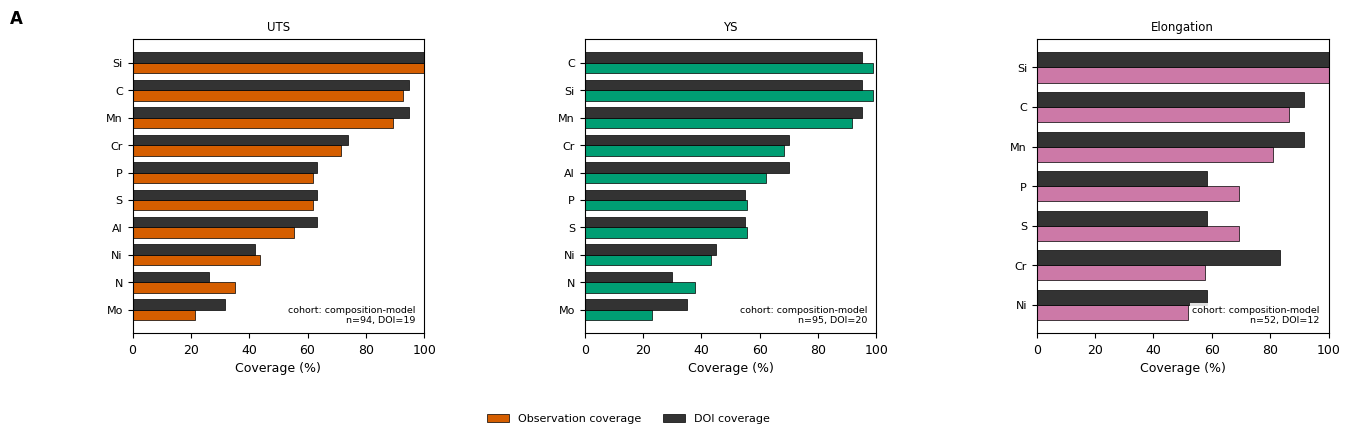

png: figures/dissertation/figC_composition_feature_coverage.png


In [5]:
has_composition = df[dc.CORE_COMPOSITION_ELEMENTS].notna().any(axis=1)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for i, target in enumerate(TARGET_ORDER):
    ax = axes[i]
    cfg = target_configs[target]
    primary_mask = ml.target_cohort_masks(df, target)["primary"]
    cohort_mask = primary_mask & has_composition
    selected_features = cfg["feature_sets"]["composition"]
    coverage = ml.composition_coverage_table(df, cohort_mask, composition_elements=selected_features)
    coverage = coverage.set_index("element").loc[selected_features].iloc[::-1]

    y = np.arange(len(coverage))
    ax.barh(y - 0.19, coverage["observation_coverage"] * 100, height=0.38,
            color=fs.TARGET_COLORS[target], edgecolor="black", linewidth=0.5, label="Observation coverage")
    ax.barh(y + 0.19, coverage["DOI_coverage"] * 100, height=0.38,
            color="#333333", edgecolor="black", linewidth=0.5, label="DOI coverage")
    ax.set_yticks(y)
    ax.set_yticklabels(coverage.index, fontsize=8)
    ax.set_xlabel("Coverage (%)")
    ax.set_xlim(0, 100)
    n_obs_cohort, n_doi_cohort = int(cohort_mask.sum()), df.loc[cohort_mask, "doi"].nunique()
    ax.text(0.97, 0.03, f"cohort: composition-model\nn={n_obs_cohort}, DOI={n_doi_cohort}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=6.8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
    ax.text(0.5, 1.02, fs.TARGET_DISPLAY[target].split(" (")[0], transform=ax.transAxes,
            ha="center", va="bottom", fontsize=8.5)
    if i == 0:
        fs.add_panel_label(ax, chr(65), x=-0.42, y=1.1)
        ax.legend(loc="lower center", bbox_to_anchor=(1.7, -0.34), ncol=2, frameon=False, fontsize=8)

fig.subplots_adjust(left=0.07, right=0.99, top=0.88, bottom=0.24, wspace=0.55)
paths = fs.save_figure(fig, "figC_composition_feature_coverage", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Figure D — mechanical-property relationships (descriptive only)

Rows present in both targets' own `primary` cohorts (not merely non-null), so every plotted point is unit-verified on both axes, using corrected UTS. It's a purely descriptive scatter — no fitted trend line, no correlation-as-causal claim — and the caption states that rows from the same DOI aren't independent.


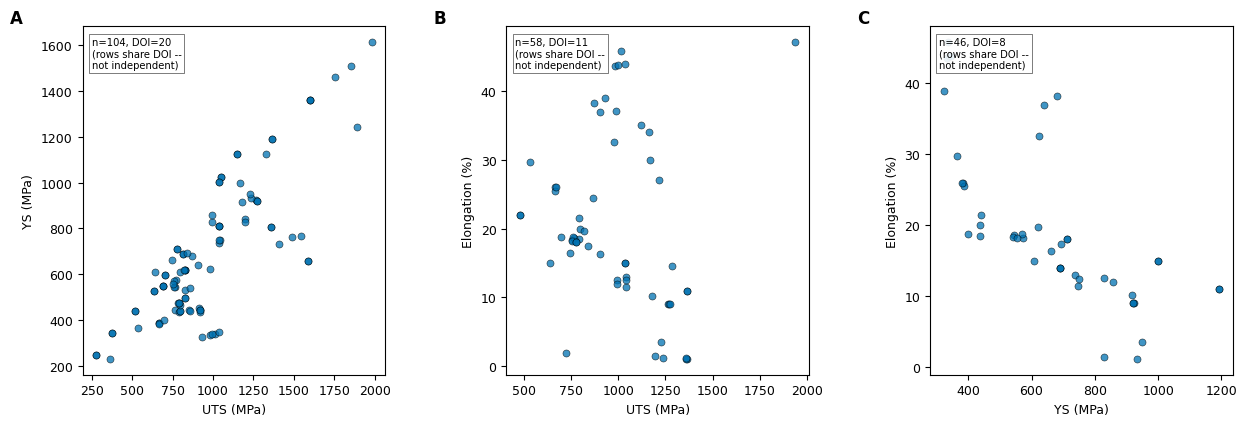

png: figures/dissertation/figD_property_relationships.png


In [6]:
primary_masks = {t: ml.target_cohort_masks(df, t)["primary"] for t in TARGET_ORDER}
value_cols = {t: target_configs[t]["model_target_column"] for t in TARGET_ORDER}
pairs = [("UTS_MPa", "YS_MPa"), ("UTS_MPa", "elongation_pct"), ("YS_MPa", "elongation_pct")]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3))
for ax, (a, b) in zip(axes, pairs):
    mask = primary_masks[a] & primary_masks[b]
    sub = df.loc[mask, [value_cols[a], value_cols[b], "doi"]].dropna()
    ax.scatter(sub[value_cols[a]], sub[value_cols[b]], color=fs.OKABE_ITO["blue"],
               edgecolor="black", linewidth=0.4, alpha=0.75, s=26)
    ax.set_xlabel(fs.TARGET_DISPLAY[a])
    ax.set_ylabel(fs.TARGET_DISPLAY[b])
    ax.text(0.03, 0.97, f"n={len(sub)}, DOI={sub['doi'].nunique()}\n(rows share DOI --\nnot independent)",
            transform=ax.transAxes, ha="left", va="top", fontsize=7.2,
            bbox=dict(facecolor="white", edgecolor="black", linewidth=0.4, alpha=0.9, pad=2))

fs.add_panel_label(axes[0], "A", x=-0.24)
fs.add_panel_label(axes[1], "B", x=-0.24)
fs.add_panel_label(axes[2], "C", x=-0.24)
fig.subplots_adjust(left=0.07, right=0.99, top=0.95, bottom=0.14, wspace=0.4)
paths = fs.save_figure(fig, "figD_property_relationships", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Figure E — model comparison against dummy (delta MAE), plus raw-metrics table

All four research models (Ridge/RF/GB/SVR) against the dummy-mean reference, one panel per target since units differ and raw MAE is never shared on one axis. Point deltas only — the publication-level bootstrap intervals are Figure G, not here. A companion raw MAE/RMSE/pooled-OOF-R² table (all 5 models) is written alongside the figure.


In [7]:
MODEL_ORDER = ["ridge", "random_forest", "gradient_boosting", "svr"]
metrics_rows = []
for target in TARGET_ORDER:
    target_slice = oof_artifact[oof_artifact["target"] == target]
    for model_name in MODEL_ORDER + ["dummy_mean"]:
        g = target_slice[target_slice["model"] == model_name]
        m = ml.compute_metrics(g["y_true"].values, g["y_pred"].values)
        metrics_rows.append({"target": target, "model": model_name, "n_obs": len(g),
                              "n_DOI": g["doi"].nunique(), "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"]})
metrics_table = pd.DataFrame(metrics_rows)
metrics_table.to_csv(OUT_DIR / "figE_model_metrics_table.csv", index=False)
print(metrics_table.round(3).to_string(index=False))


        target             model  n_obs  n_DOI     MAE    RMSE     R2
       UTS_MPa             ridge     94     19 258.898 341.990  0.111
       UTS_MPa     random_forest     94     19 200.560 269.668  0.447
       UTS_MPa gradient_boosting     94     19 202.978 283.539  0.389
       UTS_MPa               svr     94     19 310.238 396.972 -0.198
       UTS_MPa        dummy_mean     94     19 310.699 381.478 -0.106
        YS_MPa             ridge     95     20 376.020 519.705 -0.878
        YS_MPa     random_forest     95     20 266.053 381.035 -0.009
        YS_MPa gradient_boosting     95     20 260.916 386.743 -0.040
        YS_MPa               svr     95     20 321.747 406.110 -0.147
        YS_MPa        dummy_mean     95     20 311.005 391.747 -0.067
elongation_pct             ridge     52     12  14.419  18.593 -1.933
elongation_pct     random_forest     52     12   8.344  10.765  0.017
elongation_pct gradient_boosting     52     12   8.039  10.694  0.030
elongation_pct      

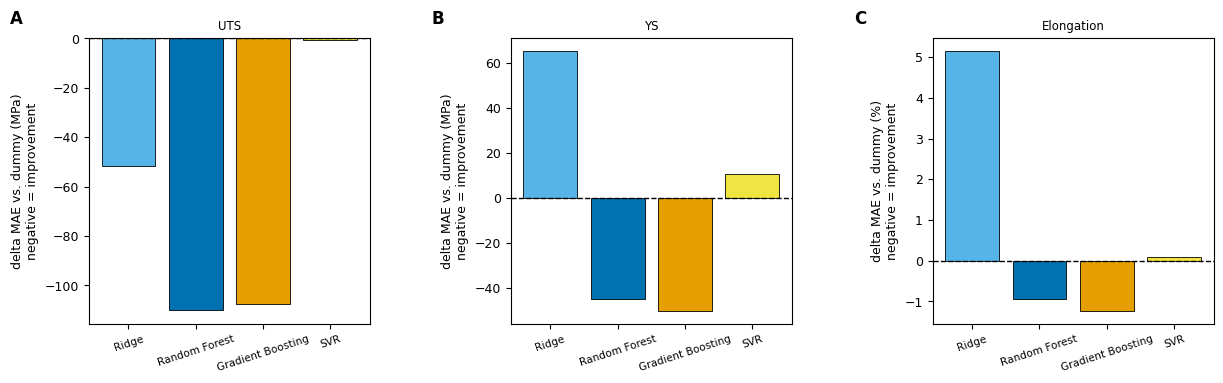

png: figures/dissertation/figE_model_comparison_vs_dummy.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.2))
for ax, target in zip(axes, TARGET_ORDER):
    sub = metrics_table[metrics_table["target"] == target].set_index("model")
    dummy_mae = sub.loc["dummy_mean", "MAE"]
    deltas = sub.loc[MODEL_ORDER, "MAE"] - dummy_mae
    colors = [fs.MODEL_COLORS[m] for m in MODEL_ORDER]
    bars = ax.bar(range(len(MODEL_ORDER)), deltas, color=colors, edgecolor="black", linewidth=0.6)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(MODEL_ORDER)))
    ax.set_xticklabels([fs.MODEL_DISPLAY[m] for m in MODEL_ORDER], fontsize=7.6, rotation=18)
    unit = fs.TARGET_DISPLAY[target].split("(")[-1].rstrip(")")
    ax.set_ylabel(f"delta MAE vs. dummy ({unit})\nnegative = improvement")
    ax.text(0.5, 1.02, fs.TARGET_DISPLAY[target].split(" (")[0], transform=ax.transAxes,
            ha="center", va="bottom", fontsize=8.5)

fs.add_panel_label(axes[0], "A", x=-0.28, y=1.1)
fs.add_panel_label(axes[1], "B", x=-0.28, y=1.1)
fs.add_panel_label(axes[2], "C", x=-0.28, y=1.1)
fig.subplots_adjust(left=0.09, right=0.99, top=0.88, bottom=0.2, wspace=0.5)
paths = fs.save_figure(fig, "figE_model_comparison_vs_dummy", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Figure F — DOI-grouped OOF actual-vs-predicted, Random Forest (principal model)

Genuine held-out OOF predictions only, read directly from the persisted artifact, no retraining. Equal aspect axes, a y=x reference line, and n/DOI/MAE/RMSE/pooled-OOF-R² annotated per panel, in corrected units.


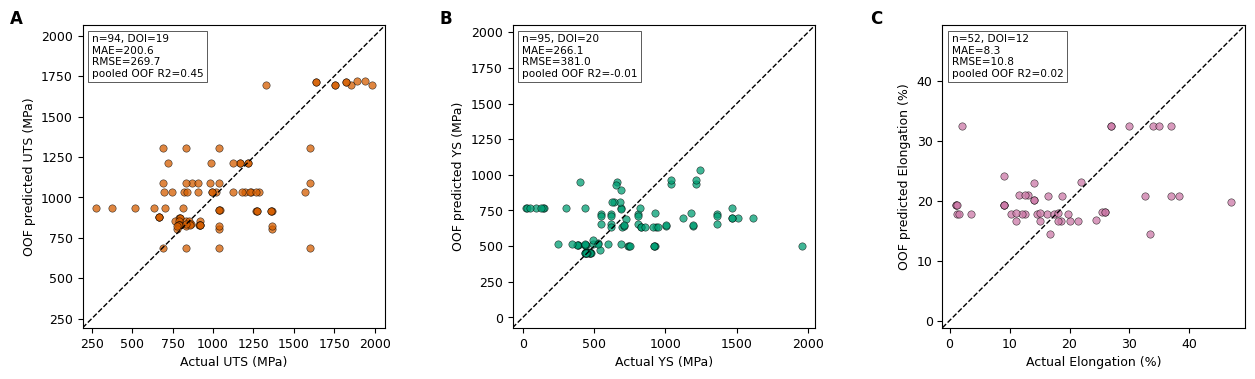

png: figures/dissertation/figF_oof_performance_principal_model.png


In [9]:
PRINCIPAL_MODEL = "random_forest"
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3))
for ax, target in zip(axes, TARGET_ORDER):
    g = oof_artifact[(oof_artifact["target"] == target) & (oof_artifact["model"] == PRINCIPAL_MODEL)]
    y_true, y_pred = g["y_true"].values, g["y_pred"].values
    m = ml.compute_metrics(y_true, y_pred)

    lo, hi = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
    pad = (hi - lo) * 0.05
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], linestyle="--", color="black", linewidth=1)
    ax.scatter(y_true, y_pred, color=fs.TARGET_COLORS[target], edgecolor="black", linewidth=0.4, alpha=0.75, s=28)
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel(f"Actual {fs.TARGET_DISPLAY[target]}")
    ax.set_ylabel(f"OOF predicted {fs.TARGET_DISPLAY[target]}")
    ax.set_aspect("equal", adjustable="box")
    n_doi = g["doi"].nunique()
    ax.text(0.03, 0.97, f"n={len(g)}, DOI={n_doi}\nMAE={m['MAE']:.1f}\nRMSE={m['RMSE']:.1f}\n"
                          f"pooled OOF R2={m['R2']:.2f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=7.6,
            bbox=dict(facecolor="white", edgecolor="black", linewidth=0.5, alpha=0.9, pad=2.5))

fs.add_panel_label(axes[0], "A", x=-0.24)
fs.add_panel_label(axes[1], "B", x=-0.24)
fs.add_panel_label(axes[2], "C", x=-0.24)
fig.subplots_adjust(left=0.06, right=0.99, top=0.95, bottom=0.14, wspace=0.42)
paths = fs.save_figure(fig, "figF_oof_performance_principal_model", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Figure G — publication-level sampling variability (paired DOI-bootstrap delta MAE)

Random Forest and Gradient Boosting against dummy, on the same fixed OOF predictions used in Figure F. B=2000, seed=42 (recorded in the figure captions document, not inside the image itself). This is publication-level sampling variability, not predictive uncertainty or general UQ.


In [10]:
N_BOOT, SEED = 2000, 42
CONTRAST_MODELS = ["random_forest", "gradient_boosting"]

contrast_results = {}
for target in TARGET_ORDER:
    target_slice = oof_artifact[oof_artifact["target"] == target]
    dummy_g = target_slice[target_slice["model"] == "dummy_mean"][IDENTITY_COLS + ["y_true", "y_pred"]]
    dummy_g = dummy_g.rename(columns={"y_pred": "y_pred_dummy", "y_true": "y_true_dummy"})
    per_model = {}
    for model_name in CONTRAST_MODELS:
        model_g = target_slice[target_slice["model"] == model_name][IDENTITY_COLS + ["y_true", "y_pred"]]
        paired = model_g.merge(dummy_g, on=IDENTITY_COLS, how="inner", validate="one_to_one")
        assert len(paired) == len(model_g) == len(dummy_g), f"{target}/{model_name}: paired contrast misalignment"
        assert (paired["y_true"] == paired["y_true_dummy"]).all()
        per_model[model_name] = ml.bootstrap_metric_contrast(
            paired["y_true"].values, paired["y_pred"].values, paired["y_pred_dummy"].values,
            paired["doi"].values, n_boot=N_BOOT, seed=SEED)
    contrast_results[target] = per_model

for target, per_model in contrast_results.items():
    for model_name, c in per_model.items():
        d = c["delta_MAE"]
        print(f"{target}/{model_name}: delta_MAE={d['point_estimate']:.2f} "
              f"[{d['ci_lower']:.2f}, {d['ci_upper']:.2f}] n_DOI={c['n_DOI']}")


UTS_MPa/random_forest: delta_MAE=-110.14 [-226.93, -30.80] n_DOI=19
UTS_MPa/gradient_boosting: delta_MAE=-107.72 [-229.33, -17.46] n_DOI=19
YS_MPa/random_forest: delta_MAE=-44.95 [-118.69, 15.64] n_DOI=20
YS_MPa/gradient_boosting: delta_MAE=-50.09 [-125.13, 14.88] n_DOI=20
elongation_pct/random_forest: delta_MAE=-0.93 [-3.56, 1.03] n_DOI=12
elongation_pct/gradient_boosting: delta_MAE=-1.24 [-2.58, 0.24] n_DOI=12


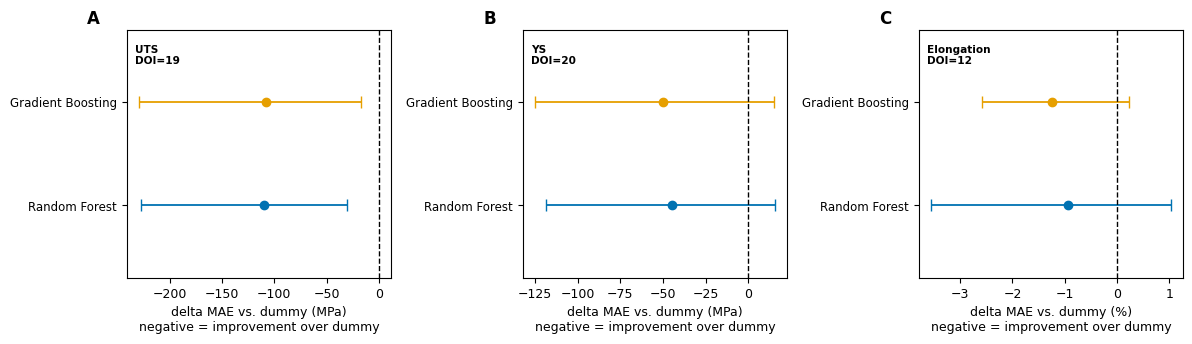

png: figures/dissertation/figG_publication_sampling_variability.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.0))
for ax, target in zip(axes, TARGET_ORDER):
    per_model = contrast_results[target]
    for yi, model_name in enumerate(CONTRAST_MODELS):
        c = per_model[model_name]["delta_MAE"]
        lo_err, hi_err = c["point_estimate"] - c["ci_lower"], c["ci_upper"] - c["point_estimate"]
        ax.errorbar(c["point_estimate"], yi, xerr=[[lo_err], [hi_err]], fmt="o",
                    color=fs.MODEL_COLORS[model_name], capsize=4, markersize=6, linewidth=1.3)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_yticks(range(len(CONTRAST_MODELS)))
    ax.set_yticklabels([fs.MODEL_DISPLAY[m] for m in CONTRAST_MODELS], fontsize=8.5)
    ax.set_ylim(-0.7, len(CONTRAST_MODELS) - 0.3)
    unit = fs.TARGET_DISPLAY[target].split("(")[-1].rstrip(")")
    ax.set_xlabel(f"delta MAE vs. dummy ({unit})\nnegative = improvement over dummy")
    n_doi = per_model[CONTRAST_MODELS[0]]["n_DOI"]
    target_short = fs.TARGET_DISPLAY[target].split(" (")[0]
    ax.text(0.03, 0.94, f"{target_short}\nDOI={n_doi}", transform=ax.transAxes, ha="left", va="top",
            fontsize=7.6, fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))

fs.add_panel_label(axes[0], "A", x=-0.15, y=1.08)
fs.add_panel_label(axes[1], "B", x=-0.15, y=1.08)
fs.add_panel_label(axes[2], "C", x=-0.15, y=1.08)
fig.subplots_adjust(left=0.1, right=0.98, top=0.9, bottom=0.28, wspace=0.5)
paths = fs.save_figure(fig, "figG_publication_sampling_variability", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Figure H — contextual completeness vs. prediction error (appendix candidate, Random Forest only)

Regenerates the minimal Notebook 04 diagnostic from the persisted OOF artifact, joined to full observation metadata via the complete identity key. The Gradient Boosting sensitivity output is a table in the appendix rather than reproduced here. This is an observational error comparison, not a causal test and not a processing/test-feature ablation — neither field is ever used as a predictor anywhere in this project.


In [12]:
def build_fig_h_frames():
    frames = {}
    for target in TARGET_ORDER:
        cfg = target_configs[target]
        value_col = cfg["model_target_column"]
        feature_cols = cfg["feature_sets"]["composition"]
        meta = df[IDENTITY_COLS + ["processing_identity_status", "test_conditions_status", value_col] +
                   feature_cols].drop_duplicates(subset=IDENTITY_COLS)

        oof_target = oof_artifact[(oof_artifact["target"] == target) &
                                   (oof_artifact["model"].isin(["random_forest", "dummy_mean"]))].copy()
        merged = oof_target.merge(meta, on=IDENTITY_COLS, how="left", validate="many_to_one")
        assert merged[value_col].isna().sum() == 0, f"{target}: unmatched OOF row(s) in Figure H join"

        merged["processing_group"] = merged["processing_identity_status"]
        merged["test_group"] = np.where(
            merged["test_conditions_status"].isin(["confirmed_explicit", "default_implicit"]),
            "resolved_or_defined", "unresolved")
        n_present = merged[feature_cols].notna().sum(axis=1)
        merged["composition_completeness"] = n_present / len(feature_cols)
        rf_slice = merged[merged["model"] == "random_forest"].copy()
        q = ml.tie_safe_quantile_groups(rf_slice["composition_completeness"], n_groups=3)
        rf_slice["completeness_group"] = q["groups"].values
        mapping = rf_slice[IDENTITY_COLS + ["completeness_group"]]
        merged = merged.merge(mapping, on=IDENTITY_COLS, how="left", validate="many_to_one")
        frames[target] = merged
    return frames

fig_h_frames = build_fig_h_frames()
DIMENSIONS_H = [
    ("processing_group", ["confirmed_baseline", "confirmed_explicit"], "Processing identity"),
    ("test_group", ["unresolved", "resolved_or_defined"], "Test information"),
    ("completeness_group", ["low", "medium", "high"], "Composition completeness"),
]
print("Figure H frames built for:", list(fig_h_frames.keys()))


Figure H frames built for: ['UTS_MPa', 'YS_MPa', 'elongation_pct']


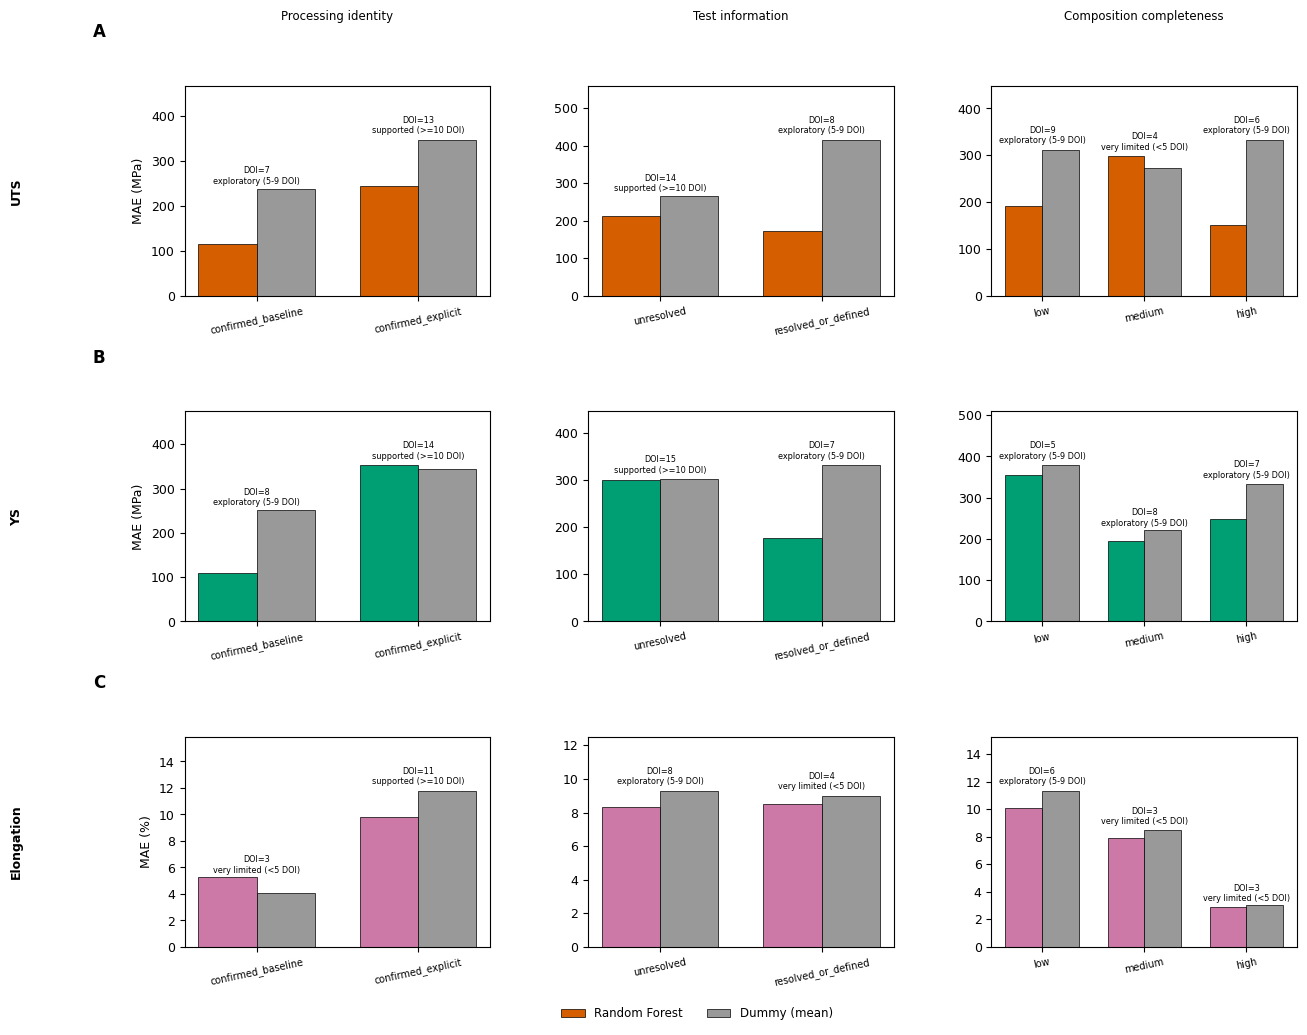

png: figures/dissertation/figH_contextual_completeness_appendix.png


In [13]:
fig, axes = plt.subplots(3, 3, figsize=(12.5, 10.5))
for row_idx, target in enumerate(TARGET_ORDER):
    merged = fig_h_frames[target]
    for col_idx, (dim, order, dim_label) in enumerate(DIMENSIONS_H):
        ax = axes[row_idx, col_idx]
        rf = merged[merged["model"] == "random_forest"]
        dummy = merged[merged["model"] == "dummy_mean"]
        present_order = [g for g in order if g in rf[dim].unique()]

        rf_table = ml.error_subgroup_table(rf, dim).set_index(dim).reindex(present_order)
        dummy_table = ml.error_subgroup_table(dummy, dim).set_index(dim).reindex(present_order)

        x = np.arange(len(present_order))
        ax.bar(x - 0.18, rf_table["MAE"], width=0.36, color=fs.TARGET_COLORS[target],
               edgecolor="black", linewidth=0.5, label="Random Forest")
        ax.bar(x + 0.18, dummy_table["MAE"], width=0.36, color=fs.OKABE_ITO["grey"],
               edgecolor="black", linewidth=0.5, label="Dummy (mean)")
        for xi, grp in enumerate(present_order):
            n_doi = int(rf_table.loc[grp, "n_DOI"])
            support = fs.support_label_display(rf_table.loc[grp, "support"])
            y = max(rf_table.loc[grp, "MAE"], dummy_table.loc[grp, "MAE"])
            ax.text(xi, y * 1.03, f"DOI={n_doi}\n{support}", ha="center", va="bottom", fontsize=5.9)
        ax.set_xticks(x)
        ax.set_xticklabels(present_order, fontsize=7, rotation=12)
        ax.set_ylim(top=ax.get_ylim()[1] * 1.28)
        if col_idx == 0:
            unit = fs.TARGET_DISPLAY[target].split("(")[-1].rstrip(")")
            ax.set_ylabel(f"MAE ({unit})")
        if row_idx == 0:
            ax.text(0.5, 1.30, dim_label, transform=ax.transAxes, ha="center", va="bottom", fontsize=8.5)
    fs.add_panel_label(axes[row_idx, 0], chr(65 + row_idx), x=-0.30, y=1.30)
    axes[row_idx, 0].text(-0.55, 0.5, fs.TARGET_DISPLAY[target].split(" (")[0],
                           transform=axes[row_idx, 0].transAxes, ha="center", va="center",
                           fontsize=9, rotation=90, fontweight="bold")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=8.5, bbox_to_anchor=(0.5, 0.0))
fig.subplots_adjust(left=0.09, right=0.98, top=0.9, bottom=0.08, hspace=0.55, wspace=0.32)
paths = fs.save_figure(fig, "figH_contextual_completeness_appendix", OUT_DIR)
for ext, p in paths.items():
    print(f"{ext}: {p.relative_to(PROJECT_ROOT)}")


## Verification summary

Prints every displayed n/DOI value per figure against the frozen manifest, so the numbers above can be cross-checked without re-reading each cell.


In [14]:
print("=== Figure F/G cohort sizes (must equal EXPECTED_N/EXPECTED_DOI) ===")
for target in TARGET_ORDER:
    print(target, EXPECTED_N[target], EXPECTED_DOI[target])
print()
print("=== Figure E/F/G metrics table ===")
print(metrics_table.round(3).to_string(index=False))


=== Figure F/G cohort sizes (must equal EXPECTED_N/EXPECTED_DOI) ===
UTS_MPa 94 19
YS_MPa 95 20
elongation_pct 52 12

=== Figure E/F/G metrics table ===
        target             model  n_obs  n_DOI     MAE    RMSE     R2
       UTS_MPa             ridge     94     19 258.898 341.990  0.111
       UTS_MPa     random_forest     94     19 200.560 269.668  0.447
       UTS_MPa gradient_boosting     94     19 202.978 283.539  0.389
       UTS_MPa               svr     94     19 310.238 396.972 -0.198
       UTS_MPa        dummy_mean     94     19 310.699 381.478 -0.106
        YS_MPa             ridge     95     20 376.020 519.705 -0.878
        YS_MPa     random_forest     95     20 266.053 381.035 -0.009
        YS_MPa gradient_boosting     95     20 260.916 386.743 -0.040
        YS_MPa               svr     95     20 321.747 406.110 -0.147
        YS_MPa        dummy_mean     95     20 311.005 391.747 -0.067
elongation_pct             ridge     52     12  14.419  18.593 -1.933
elongat